# RotaViva — Previsão de risco de sinistros com motos em São Paulo

**Problema:** em 2026 a cidade de São Paulo bateu recorde de mortes de motociclistas (Infosiga/Detran-SP).

**Pergunta de ML:** dado o dia, o horário, a região e a chuva, qual o nível de risco de sinistros com moto?

**Objetivo para o cidadão:** alertar o motociclista para redobrar a atenção e ajudar órgãos como CET, PM, SAMU e Bombeiros a planejar patrulhas e equipes nos horários e locais mais críticos.

**Fontes de dados (reais e públicas):**
- Infosiga SP (Detran-SP): sinistros de trânsito — https://infosiga.detran.sp.gov.br/
- INMET: dados meteorológicos horários da estação A701 (São Paulo - Mirante) — https://portal.inmet.gov.br/dadoshistoricos

## 1. Bibliotecas e pastas

In [1]:
import pandas as pd               # manipulação das tabelas
import matplotlib.pyplot as plt   # gráficos
from pathlib import Path          # caminhos de pastas
import numpy as np
# pastas onde estão os arquivos baixados
pasta_infosiga = Path("dados/infosiga")
pasta_inmet = Path("dados/inmet")

## 2. Carregando os sinistros do Infosiga

O Infosiga disponibiliza três bases (sinistros, pessoas e veículos), divididas por período.
Para o nosso problema, a base de **sinistros** já basta: ela tem data, hora, localização, quantidade de motos envolvidas e gravidade.

Carregamos apenas as colunas necessárias, para economizar memória, e filtramos a **cidade de São Paulo**.

In [2]:
# colunas que vamos usar da base de sinistros
colunas = [
    "id_sinistro", "tipo_registro", "data_sinistro", "hora_sinistro", "dia_da_semana",
    "turno", "logradouro", "tipo_via", "latitude", "longitude", "municipio",
    "tp_sinistro_primario", "qtd_motocicleta",
    "qtd_gravidade_fatal", "qtd_gravidade_grave", "qtd_gravidade_leve",
]

def ler(arquivo):
    # os arquivos usam ";" como separador; tentamos utf-8 e, se der erro, latin-1
    try:
        return pd.read_csv(arquivo, sep=";", usecols=colunas, encoding="utf-8", low_memory=False)
    except UnicodeDecodeError:
        return pd.read_csv(arquivo, sep=";", usecols=colunas, encoding="latin-1", low_memory=False)

# junta os 3 períodos (2015-2021, 2022-2024, 2025-2026) em uma tabela só
arquivos = sorted(pasta_infosiga.glob("sinistros_*.csv"))
sinistros = pd.concat([ler(a) for a in arquivos], ignore_index=True)

# mantém apenas a capital
sp = sinistros[sinistros["municipio"] == "SAO PAULO"].copy()

print("Estado inteiro:", len(sinistros))
print("Cidade de SP:  ", len(sp))

Estado inteiro: 1450961
Cidade de SP:   343241


## 3. Ajustando os tipos das colunas

Os dados vêm como texto, então precisamos converter:
- `data_sinistro` → data
- `hora_sinistro` ("18:30") → só a hora (18)
- `latitude` / `longitude` → número (vêm com vírgula no lugar do ponto)

Também criamos duas colunas de apoio:
- `moto` = 1 se havia pelo menos uma moto envolvida
- `fatal` = 1 se houve pelo menos uma morte

In [3]:
# data no formato dia/mês/ano
sp["data"] = pd.to_datetime(sp["data_sinistro"], format="%d/%m/%Y", errors="coerce")
sp["ano"] = sp["data"].dt.year

# pega os 2 primeiros caracteres de "18:30" -> 18
sp["hora"] = pd.to_numeric(sp["hora_sinistro"].str[:2], errors="coerce")

# troca vírgula por ponto para virar número
sp["lat"] = pd.to_numeric(sp["latitude"].astype(str).str.replace(",", "."), errors="coerce")
sp["lon"] = pd.to_numeric(sp["longitude"].astype(str).str.replace(",", "."), errors="coerce")

# vazio na contagem significa zero
sp["moto"] = (sp["qtd_motocicleta"].fillna(0) > 0).astype(int)
sp["fatal"] = (sp["qtd_gravidade_fatal"].fillna(0) > 0).astype(int)

sp[["data", "hora", "lat", "lon", "moto", "fatal"]].head()

,data,hora,lat,lon,moto,fatal
3,2015-01-01,5.0,-23.514670,-46.469080,1,1
6,2015-01-02,2.0,-23.680046,-46.776032,1,1
11,2015-01-05,17.0,-23.683411,-46.789255,1,1
12,2015-01-06,17.0,-23.563159,-46.589671,0,1
30,2015-01-17,5.0,-23.527590,-46.568203,0,1


## 4. Visão geral da base

Antes de modelar, verificamos:
- quais tipos de registro existem e como se distribuem por ano;
- quanto falta de hora e de coordenadas (essenciais para o modelo);
- a participação das motos nos sinistros.

In [4]:
print("Tipos de registro:")
print(sp["tipo_registro"].value_counts(), "\n")

# quantos registros de cada tipo existem em cada ano
print("Registros por ano e tipo:")
print(pd.crosstab(sp["ano"], sp["tipo_registro"]), "\n")

# a hora é essencial para o modelo, então vemos quanto falta em cada ano
print("% sem hora por ano:")
print((sp.groupby("ano")["hora"].apply(lambda h: h.isna().mean()) * 100).round(1), "\n")

print(f"Sem coordenadas: {sp['lat'].isna().mean():.1%}")
print(f"Com moto:        {sp['moto'].mean():.1%}")

Tipos de registro:
tipo_registro
SINISTRO NAO FATAL    210271
NOTIFICACAO           122719
SINISTRO FATAL         10251
Name: count, dtype: int64 

Registros por ano e tipo:
tipo_registro  NOTIFICACAO  SINISTRO FATAL  SINISTRO NAO FATAL
ano                                                           
2014                     0               2                   0
2015                     0            1062                   0
2016                     0             891                   0
2017                     0             790                   0
2018                     0             813                   0
2019                 15546             767               28003
2020                 12857             680               25214
2021                 16176             710               27419
2022                 15863             844               27617
2023                 16100             900               29450
2024                 15930            1011               28633
2025   

## 5. Quando acontecem os sinistros com moto?

Olhamos só os sinistros **com moto**, de **2019 em diante**, porque é a partir de 2019 que o Infosiga passou a incluir também os sinistros não fatais.

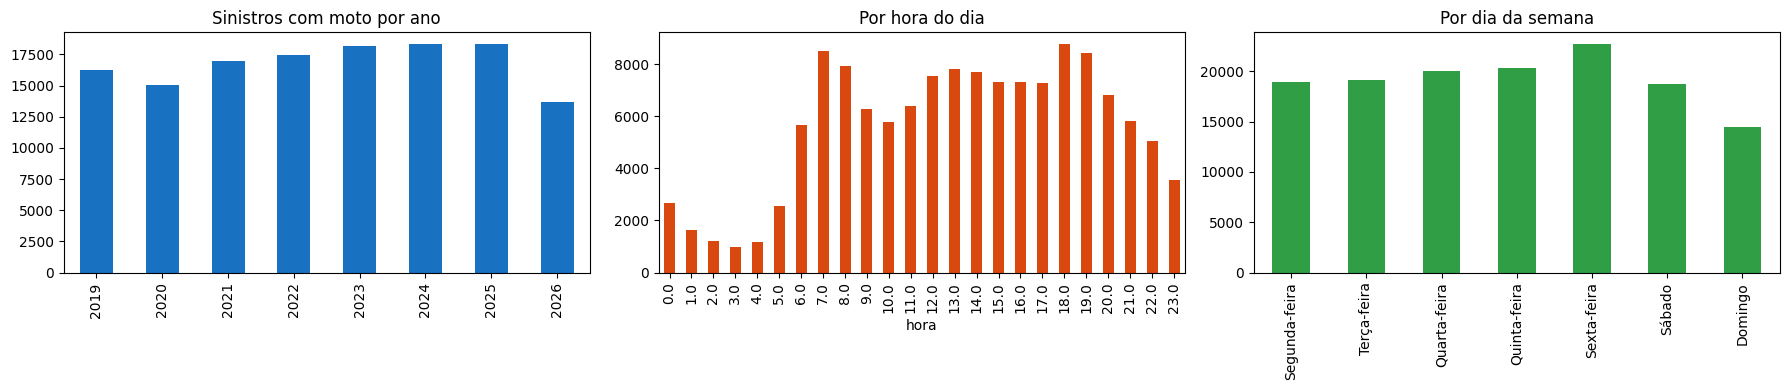

In [5]:
# só sinistros com moto, a partir de 2019
moto = sp[(sp["moto"] == 1) & (sp["ano"] >= 2019)]

fig, eixos = plt.subplots(1, 3, figsize=(18, 4))

# quantidade por ano
moto.groupby("ano").size().plot(kind="bar", ax=eixos[0], color="#1971c2")
eixos[0].set_title("Sinistros com moto por ano")
eixos[0].set_xlabel("")

# quantidade por hora do dia
moto["hora"].value_counts().sort_index().plot(kind="bar", ax=eixos[1], color="#d9480f")
eixos[1].set_title("Por hora do dia")
eixos[1].set_xlabel("hora")

# quantidade por dia da semana (na ordem certa)
ordem = ["Segunda-feira", "Terça-feira", "Quarta-feira", "Quinta-feira",
         "Sexta-feira", "Sábado", "Domingo"]
moto["dia_da_semana"].value_counts().reindex(ordem).plot(kind="bar", ax=eixos[2], color="#2f9e44")
eixos[2].set_title("Por dia da semana")
eixos[2].set_xlabel("")

plt.tight_layout()
plt.show()

### 5.1 Em que horário os sinistros com moto são mais letais?

Quantidade de sinistros e gravidade são coisas diferentes: um horário pode ter poucos sinistros, mas uma proporção maior de mortes.

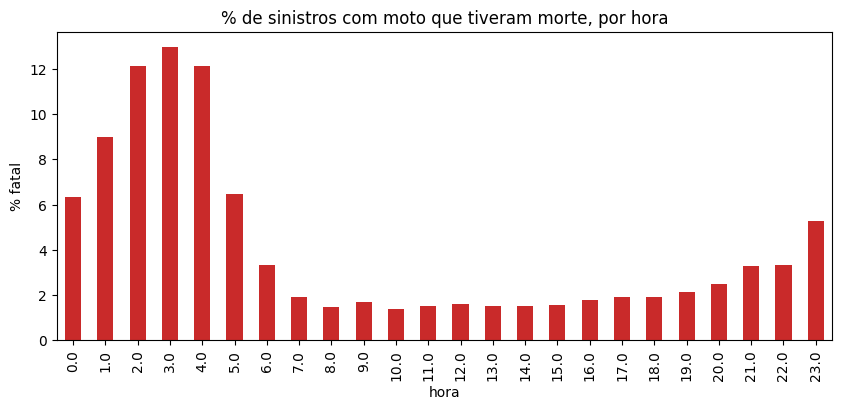

In [6]:
# % dos sinistros com moto que tiveram pelo menos uma morte, por hora
taxa_fatal = moto.groupby("hora")["fatal"].mean() * 100

taxa_fatal.plot(kind="bar", figsize=(10, 4), color="#c92a2a")
plt.title("% de sinistros com moto que tiveram morte, por hora")
plt.ylabel("% fatal")
plt.xlabel("hora")
plt.show()

## 6. Carregando os dados de chuva (INMET)

Formato dos arquivos do INMET:
- as **8 primeiras linhas** são informações da estação, então pulamos essas linhas;
- separador `;` e decimal com vírgula;
- dado faltante aparece como `-9999`;
- a hora está em **UTC**, então subtraímos 3 horas para o horário de Brasília.

In [7]:
partes = []

for arquivo in sorted(pasta_inmet.glob("*.CSV")):
    df = pd.read_csv(arquivo, sep =";", encoding="latin-1", skiprows = 8, decimal=",", na_values=["-9999"])

    # os nomes das colunas têm acento, então procuramos por um trecho do nome
    col_chuva = [c for c in df.columns if "PRECIPITA" in c.upper()][0]
    col_temp = [c for c in df.columns if "BULBO SECO" in c.upper()][0]

    # "Hora UTC" vem como "1800 UTC" -> pegamos "1800" e montamos "18:00"
    hora_utc = df["Hora UTC"].astype(str).str[:4]
    datahora = pd.to_datetime(df["Data"].astype(str).str.replace("/", "-") + " "
                              + hora_utc.str[:2] + ":" + hora_utc.str[2:])

    partes.append(pd.DataFrame({
        "datahora": datahora - pd.Timedelta(hours=3),  # UTC -> horário de Brasília
        "chuva_mm": df[col_chuva],
        "temp_c": df[col_temp],
    }))

# junta todos os anos
clima = pd.concat(partes, ignore_index=True).sort_values("datahora")

print(f"{len(clima)} horas de {clima['datahora'].min()} até {clima['datahora'].max()}")
print(f"Horas sem dado de chuva: {clima['chuva_mm'].isna().mean():.1%}")
clima.head()

68664 horas de 2018-12-31 21:00:00 até 2026-10-31 20:00:00
Horas sem dado de chuva: 1.2%


,datahora,chuva_mm,temp_c
0,2018-12-31 21:00:00,0.0,22.8
1,2018-12-31 22:00:00,0.0,22.3
2,2018-12-31 23:00:00,0.0,22.1
3,2019-01-01 00:00:00,0.0,21.6
4,2019-01-01 01:00:00,0.0,21.6


## 7. Chuva aumenta os sinistros com moto?

Primeiro teste da hipótese: contamos os sinistros com moto em cada hora e comparamos a média nas horas **com chuva** e **sem chuva**.

In [8]:
# monta a data + hora de cada sinistro (ex.: 2024-03-10 18:00)

moto_hora = moto.dropna(subset=["data", "hora"]).copy()
moto_hora["datahora"] = moto_hora["data"] + pd.to_timedelta(moto_hora["hora"], unit="h")

# quantos sinistros com moto aconteceram em cada hora
contagem = moto_hora.groupby("datahora").size().rename("sinistros_moto")

# junta com a chuva da mesma hora (horas sem sinistro ficam com 0)

juntos = clima.dropna(subset=["chuva_mm"]).set_index("datahora")
juntos = juntos.loc[contagem.index.min():contagem.index.max()]
juntos = juntos.join(contagem).fillna({"sinistros_moto":0})
juntos["choveu"] = juntos["chuva_mm"] > 0


# média de sinistros com moto por hora, com e sem chuva
juntos.groupby("choveu")["sinistros_moto"].agg(["mean", "count"]).round(3)

,mean,count
choveu,,
False,1.979,61836
True,1.936,5308


### 7.1 Chuva × sinistros comparando no mesmo horário

A comparação anterior pode enganar: chove mais à tarde, e o número de sinistros também muda com o horário.
Aqui comparamos **hora a hora** e separamos a chuva por intensidade.

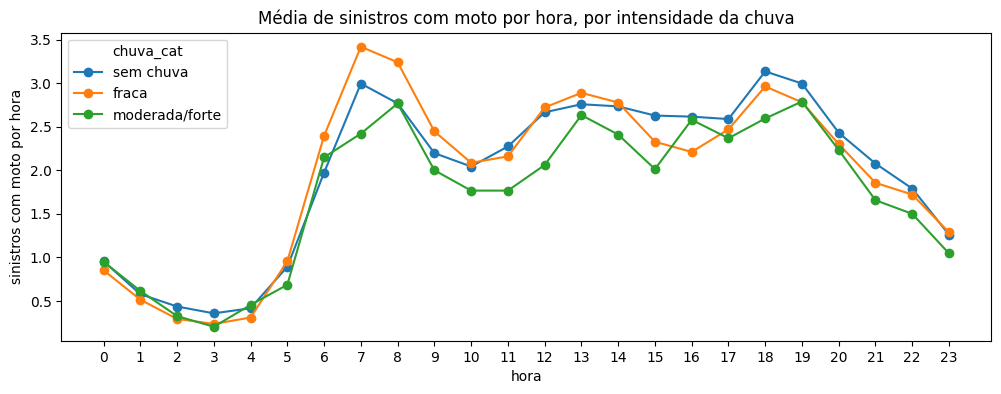

,mean,count
chuva_cat,,
sem chuva,1.979,61836
fraca,1.963,3930
moderada/forte,1.861,1378


In [9]:
# hora do dia de cada linha

juntos["hora"] = juntos.index.hour

# classifica a chuva por intennsidade
juntos["chuva_cat"] = pd.cut(
    juntos["chuva_mm"],
    bins=[-0.1, 0, 2, 1000],
    labels=["sem chuva", "fraca", "moderada/forte"],
)

# média de sinistros com moto por hora, separada pela intensidade da chuva

tabela = juntos.pivot_table(index="hora", columns="chuva_cat", values="sinistros_moto", aggfunc="mean", observed=False)
tabela.plot(figsize=(12,4), marker="o")
plt.title("Média de sinistros com moto por hora, por intensidade da chuva")
plt.ylabel("sinistros com moto por hora")
plt.xticks(range(24))
plt.show()

# resumo geral por intensidade
juntos.groupby("chuva_cat", observed=False)["sinistros_moto"].agg(["mean", "count"]).round(3)

## 8. Base final de sinistros com moto

Critérios:
- somente **sinistros confirmados** (fatais e não fatais); registros do tipo `NOTIFICACAO` são avisos ainda não confirmados;
- a partir de **2019** (antes disso o Infosiga só registrava sinistros fatais);
- somente sinistros **com moto**;
- precisa ter **hora** e **coordenadas** válidas dentro da cidade.

In [10]:
# sinistros confirmados, com moto, de 2019 em diante

base = sp[
    (sp["tipo_registro"] != "NOTIFICACAO")
    & (sp["ano"]>= 2019)
    & (sp["moto"] == 1)
].copy()

print("sinistros com moto (2019+):", len(base))

# remove linhas sem hora ou sem coordenadas
base = base.dropna(subset=["hora", "lat", "lon"])

# remove coordenadas fora dos limites aproximados da cidade (erros de digitação)
base = base[base["lat"].between(-24.01, -23.35) & base["lon"].between(-46.83, -46.36)]
print("Depois da limpeza:          ", len(base))

sinistros com moto (2019+): 134338
Depois da limpeza:           129069


## 9. Dividindo a cidade em zonas

Para indicar **onde** o risco é maior, dividimos a cidade em 5 zonas a partir do **Marco Zero (Praça da Sé)**:
- até 5 km do Marco Zero → **Centro**
- além disso, a direção em relação ao Marco Zero define **Norte, Sul, Leste ou Oeste**

É uma aproximação das zonas oficiais, simples de explicar e suficiente para orientar patrulhas e alertas.

zona
Sul       37633
Leste     31602
Oeste     28152
Centro    18267
Norte     13415
Name: count, dtype: int64


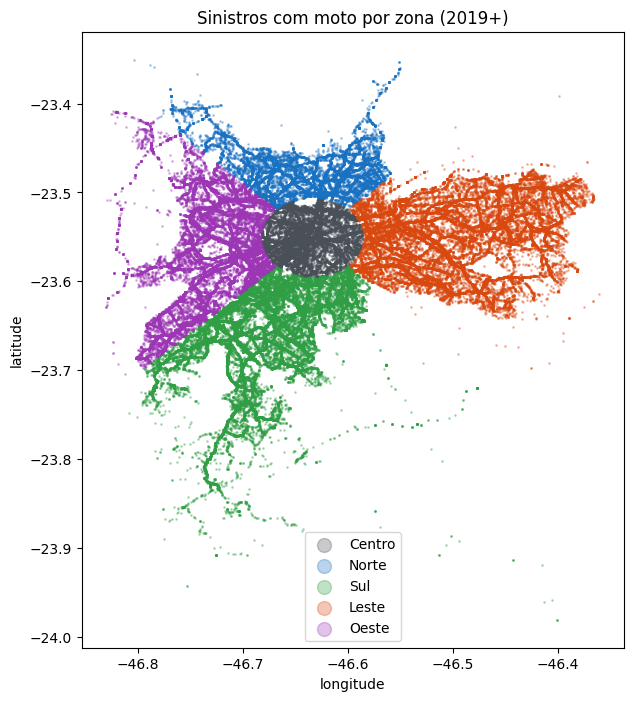

In [11]:
# coordenadas do Marco Zero de São Paulo (Praça da Sé)
MARCO_ZERO_LAT, MARCO_ZERO_LON = -23.5505, -46.6340
# distância aproximada em km (1 grau de latitude ≈ 111 km)
dy = (base["lat"]- MARCO_ZERO_LAT) * 111
dx = (base["lon"]- MARCO_ZERO_LON) * 111 * np.cos(np.radians(MARCO_ZERO_LAT))
distancia_km = np.sqrt(dx**2 + dy**2)

# ângulo em graus: 0 = leste, 90 = norte, 180 = oeste, -90 = sul

angulo = np.degrees(np.arctan2(dy, dx))

base["zona"] = np.select(
    [
        distancia_km <= 5,
        angulo.between(45, 135),
        angulo.between(-45, 45),
        angulo.between(-135, -45),
    ],
    ["Centro", "Norte", "Leste", "Sul"],
    default="Oeste",
)

print(base["zona"].value_counts())

# mapa para conferir se as zonas fazem sentido

cores = {"Centro": "#495057", "Norte": "#1971c2", "Sul": "#2f9e44",
         "Leste": "#d9480f", "Oeste": "#9c36b5"}
plt.figure(figsize=(7,8))
for zona, cor in cores.items():
    pontos = base[base["zona"]== zona]
    plt.scatter(pontos["lon"], pontos["lat"], s=1, alpha=0.3, color=cor, label=zona)
plt.legend(markerscale=10)
plt.title("Sinistros com moto por zona (2019+)")
plt.xlabel("longitude")
plt.ylabel("latitude")
plt.show()

## 10. Montando a base de treino

Cada linha da base de treino representa **uma zona, em um dia, em uma faixa de 3 horas**:

| faixa | horário |
|---|---|
| 0 | 00h–03h |
| 1 | 03h–06h |
| 2 | 06h–09h |
| 3 | 09h–12h |
| 4 | 12h–15h |
| 5 | 15h–18h |
| 6 | 18h–21h |
| 7 | 21h–24h |

**Alvo (o que o modelo vai prever):** quantidade de sinistros com moto naquela zona/dia/faixa.

**Variáveis de entrada**, todas conhecidas *antes* de o sinistro acontecer:
- zona, faixa horária, dia da semana, fim de semana, mês, ano, feriado;
- chuva na faixa, chuva na faixa anterior (pista molhada) e temperatura média.

Importante: precisamos incluir também as combinações **sem nenhum sinistro** (contagem = 0). Sem elas, o modelo nunca aprenderia como é um período tranquilo.

In [12]:
from dateutil.easter import easter   # já vem instalado junto com o pandas

# faixa de 3 horas: hora 0-2 -> 0, 3-5 -> 1, ..., 21-23 -> 7
base["faixa"] = (base["hora"] // 3).astype(int)

# conta quantos sinistros com moto houve em cada zona/dia/faixa
contagem = base.groupby(["zona", "data", "faixa"]).size().rename("sinistros_moto")

# cria TODAS as combinações possíveis de zona x dia x faixa
zonas = sorted(base["zona"].unique())
dias = pd.date_range(base["data"].min(), base["data"].max(), freq="D")
grade = pd.MultiIndex.from_product([zonas, dias, range(8)], names=["zona", "data", "faixa"])

# combinações que não estão na contagem recebem 0
treino_base = contagem.reindex(grade, fill_value=0).reset_index()

print("Linhas:", len(treino_base))
print(f"Linhas com zero sinistros: {(treino_base['sinistros_moto'] == 0).mean():.1%}")

Linhas: 113200
Linhas com zero sinistros: 40.9%


### 10.1 Adicionando chuva e temperatura

Agrupamos os dados horários do INMET nas mesmas faixas de 3 horas:
- `chuva_mm`: chuva total na faixa
- `chuva_faixa_anterior_mm`: chuva nas 3 horas anteriores (a pista pode continuar molhada)
- `temp_c`: temperatura média na faixa

Horas sem medição ficam vazias (NaN). O XGBoost sabe lidar com valores faltantes, então não precisamos inventar valores.

In [13]:
clima["data"] = clima["datahora"].dt.normalize()   # só o dia, sem a hora
clima["faixa"] = clima["datahora"].dt.hour // 3

# soma da chuva e média da temperatura em cada faixa
# min_count=1: se todas as horas da faixa estiverem sem dado, o resultado fica NaN (e não 0)
clima_faixa = (
    clima.groupby(["data", "faixa"])
    .agg(chuva_mm=("chuva_mm", lambda s: s.sum(min_count=1)),
         temp_c=("temp_c", "mean"))
    .reset_index()
    .sort_values(["data", "faixa"])
)

# chuva da faixa anterior (desloca a coluna uma linha para baixo)
clima_faixa["chuva_faixa_anterior_mm"] = clima_faixa["chuva_mm"].shift(1)

# junta com a base de treino pela data e faixa
treino_base = treino_base.merge(clima_faixa, on=["data", "faixa"], how="left")
treino_base[["chuva_mm", "chuva_faixa_anterior_mm", "temp_c"]].describe()

,chuva_mm,chuva_faixa_anterior_mm,temp_c
count,112200.000000,112200.000000,112910.000000
mean,0.537487,0.537487,20.638048
std,2.994070,2.994070,4.549547
min,0.000000,0.000000,4.600000
25%,0.000000,0.000000,17.433333
50%,0.000000,0.000000,20.433333
75%,0.000000,0.000000,23.500000
max,121.800000,121.800000,36.466667


### 10.2 Variáveis de calendário e feriados

Feriados considerados (nacionais, estaduais de SP e municipais da capital):
- datas fixas: 1/jan, 25/jan (aniversário de SP), 21/abr, 1/mai, 9/jul, 7/set, 12/out, 2/nov, 15/nov, 20/nov, 25/dez;
- datas móveis, calculadas a partir da Páscoa: Carnaval (segunda e terça), Sexta-feira Santa e Corpus Christi.

In [14]:
def feriados_sp(anos):
    datas = []
    for ano in anos:
        # feriados de data fixa
        for mes, dia in [(1, 1), (1, 25), (4, 21), (5, 1), (7, 9), (9, 7),
                         (10, 12), (11, 2), (11, 15), (11, 20), (12, 25)]:
            datas.append(pd.Timestamp(ano, mes, dia))
        # feriados que dependem da Páscoa
        pascoa = pd.Timestamp(easter(ano))
        datas += [
            pascoa - pd.Timedelta(days=48),   # segunda de Carnaval
            pascoa - pd.Timedelta(days=47),   # terça de Carnaval
            pascoa - pd.Timedelta(days=2),    # Sexta-feira Santa
            pascoa + pd.Timedelta(days=60),   # Corpus Christi
        ]
    return set(datas)

feriados = feriados_sp(range(2019, 2027))

treino_base["dia_semana"] = treino_base["data"].dt.dayofweek          # 0 = segunda ... 6 = domingo
treino_base["fim_de_semana"] = (treino_base["dia_semana"] >= 5).astype(int)
treino_base["mes"] = treino_base["data"].dt.month
treino_base["ano"] = treino_base["data"].dt.year
treino_base["feriado"] = treino_base["data"].isin(feriados).astype(int)

print("Dias de feriado na base:", treino_base.loc[treino_base["feriado"] == 1, "data"].nunique())
treino_base.head()

Dias de feriado na base: 115


,zona,data,faixa,sinistros_moto,chuva_mm,temp_c,chuva_faixa_anterior_mm,dia_semana,fim_de_semana,mes,ano,feriado
0,Centro,2019-01-01,0,1,0.0,21.533333,0.0,1,0,1,2019,1
1,Centro,2019-01-01,1,0,0.0,20.866667,0.0,1,0,1,2019,1
2,Centro,2019-01-01,2,0,0.0,22.566667,0.0,1,0,1,2019,1
3,Centro,2019-01-01,3,0,0.0,27.500000,0.0,1,0,1,2019,1
4,Centro,2019-01-01,4,0,0.0,30.333333,0.0,1,0,1,2019,1


## 11. Onde e quando o risco é maior?

Média de sinistros com moto por zona e faixa horária. Essa visão já responde à pergunta dos órgãos de segurança: **onde e quando concentrar patrulhas e equipes**.

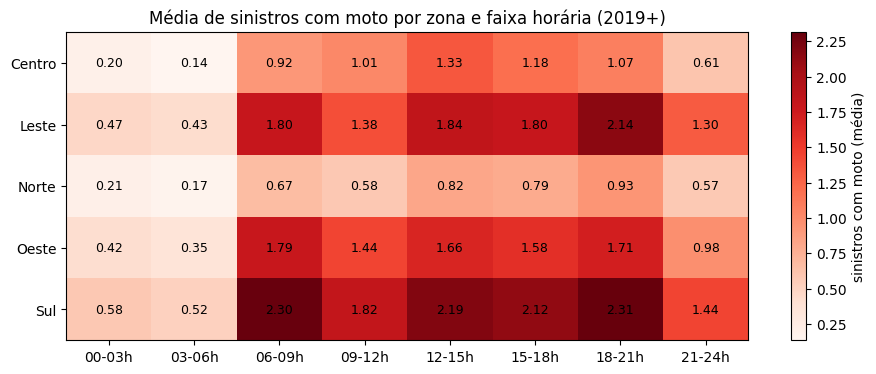

Base de treino salva: (113200, 12)


In [15]:
# média de sinistros por zona (linhas) e faixa (colunas)
mapa_calor = treino_base.pivot_table(index="zona", columns="faixa",
                                     values="sinistros_moto", aggfunc="mean")
rotulos = ["00-03h", "03-06h", "06-09h", "09-12h", "12-15h", "15-18h", "18-21h", "21-24h"]

fig, ax = plt.subplots(figsize=(11, 4))
img = ax.imshow(mapa_calor, cmap="Reds", aspect="auto")
ax.set_xticks(range(8), rotulos)
ax.set_yticks(range(len(mapa_calor)), mapa_calor.index)

# escreve o valor dentro de cada quadrado
for i in range(mapa_calor.shape[0]):
    for j in range(mapa_calor.shape[1]):
        ax.text(j, i, f"{mapa_calor.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)

plt.colorbar(img, label="sinistros com moto (média)")
plt.title("Média de sinistros com moto por zona e faixa horária (2019+)")
plt.show()

# salva a base de treino para usar na etapa do modelo
treino_base.to_csv("dados/base_treino.csv", index=False)
print("Base de treino salva:", treino_base.shape)

## 11.5 Variável de histórico recente

No primeiro experimento, o modelo empatou com o baseline e superestimou o período de teste: os sinistros confirmados caíram em 2025, e o modelo só conhecia o patamar até 2024.

Para que ele perceba mudanças de patamar, criamos `historico_30d`: a média de sinistros da **mesma zona e faixa** nos 30 dias anteriores ao último mês (de 60 a 31 dias atrás).
Usamos essa defasagem porque o Infosiga é atualizado mensalmente: só usamos dados que já estariam publicados no momento da previsão (sem "espiar o futuro").

In [16]:
# ordena cada série (zona + faixa) por data
treino_base = treino_base.sort_values(["zona", "faixa", "data"]).reset_index(drop=True)

# shift(30): volta 30 dias  |  rolling(30): média dos 30 dias anteriores a isso
treino_base["historico_30d"] = (
    treino_base.groupby(["zona", "faixa"])["sinistros_moto"]
    .transform(lambda s: s.shift(30).rolling(30, min_periods=15).mean())
)

# os primeiros ~2 meses de 2019 ficam vazios (não há histórico); o XGBoost lida com isso
print(f"Linhas sem histórico: {treino_base['historico_30d'].isna().mean():.1%}")
treino_base[["zona", "faixa", "data", "sinistros_moto", "historico_30d"]].tail()

Linhas sem histórico: 1.6%


,zona,faixa,data,sinistros_moto,historico_30d
113195,Sul,7,2026-09-26,2,1.766667
113196,Sul,7,2026-09-27,1,1.833333
113197,Sul,7,2026-09-28,1,1.900000
113198,Sul,7,2026-09-29,1,1.900000
113199,Sul,7,2026-09-30,1,1.866667


## 12. Preparando os dados para o modelo

### 12.1 Variáveis de entrada (X) e alvo (y)

A zona é texto, e o modelo só entende números. Por isso, usamos **one-hot encoding**: cada zona vira uma coluna com 0 ou 1 (`zona_Sul`, `zona_Leste`...).

In [17]:
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ordena por tempo (necessário para a validação temporal)
treino_base = treino_base.sort_values(["data", "faixa", "zona"]).reset_index(drop=True)

# versão 2: sai "ano" (árvores não extrapolam anos novos) e "fim_de_semana" (já coberto por dia_semana)
#            entra "historico_30d" (patamar recente de sinistros da zona/faixa)
features_numericas = ["faixa", "dia_semana", "mes", "feriado",
                      "chuva_mm", "chuva_faixa_anterior_mm", "temp_c", "historico_30d"]

# one-hot da zona: vira zona_Centro, zona_Leste, zona_Norte, zona_Oeste, zona_Sul
X = pd.get_dummies(treino_base[features_numericas + ["zona"]], columns=["zona"], dtype=int)
y = treino_base["sinistros_moto"]

print("Colunas usadas pelo modelo:", list(X.columns))

Colunas usadas pelo modelo: ['faixa', 'dia_semana', 'mes', 'feriado', 'chuva_mm', 'chuva_faixa_anterior_mm', 'temp_c', 'historico_30d', 'zona_Centro', 'zona_Leste', 'zona_Norte', 'zona_Oeste', 'zona_Sul']


### 12.2 Divisão treino × teste (temporal)

Não usamos divisão aleatória: ela misturaria dias do futuro no treino.
Separamos pelo tempo, simulando o uso real (aprender com o passado e prever o futuro):
- **Treino:** 2019 a 2024
- **Teste:** 2025 a 2026 (o modelo nunca viu esses dados)

In [18]:
eh_treino = treino_base["ano"] <= 2024

X_treino, y_treino = X[eh_treino], y[eh_treino]
X_teste, y_teste = X[~eh_treino], y[~eh_treino]

print(f"Treino: {len(X_treino):,} linhas "
      f"({treino_base.loc[eh_treino, 'data'].min():%d/%m/%Y} a {treino_base.loc[eh_treino, 'data'].max():%d/%m/%Y})")
print(f"Teste:  {len(X_teste):,} linhas "
      f"({treino_base.loc[~eh_treino, 'data'].min():%d/%m/%Y} a {treino_base.loc[~eh_treino, 'data'].max():%d/%m/%Y})")

Treino: 87,680 linhas (01/01/2019 a 31/12/2024)
Teste:  25,520 linhas (01/01/2025 a 30/09/2026)


## 13. Baseline: o modelo precisa vencer uma regra simples

Antes do XGBoost, criamos uma previsão "ingênua": a **média histórica** de sinistros por zona + faixa horária + fim de semana.
Se o modelo não for melhor que isso, ele não está agregando valor.

In [19]:
chave = ["zona", "faixa", "fim_de_semana"]

# média de sinistros no treino para cada combinação da chave
media_hist = treino_base[eh_treino].groupby(chave)["sinistros_moto"].mean().rename("previsao_baseline")

# aplica essa média como "previsão" no período de teste
baseline_teste = treino_base[~eh_treino].merge(media_hist, on=chave, how="left")["previsao_baseline"]

print(f"Baseline — MAE no teste: {mean_absolute_error(y_teste, baseline_teste):.3f}")

Baseline — MAE no teste: 0.822


## 14. Treinando o XGBoost com diferentes hiperparâmetros

**Por que XGBoost?**
- funciona muito bem com dados em tabela;
- captura **interações** entre variáveis (ex.: chuva fraca *no horário de pico* aumenta os sinistros, mas chuva forte diminui — visto na seção 7.1);
- lida sozinho com valores faltantes (horas sem medição de chuva);
- tem o objetivo **`count:poisson`**, próprio para prever **contagens** (0, 1, 2, 3...).

**Hiperparâmetros testados (3 × 2 × 2 = 12 combinações):**
- `max_depth`: profundidade das árvores (3, 5, 7) → árvores mais profundas aprendem padrões mais complexos, mas podem decorar o treino;
- `learning_rate`: tamanho do passo de aprendizado (0.05, 0.1);
- `n_estimators`: quantidade de árvores (200, 500).

**Validação cruzada só no treino**, com `TimeSeriesSplit` (3 divisões em ordem cronológica): o modelo sempre valida em um período **posterior** ao que treinou.

In [20]:
modelo_base = XGBRegressor(
    objective="count:poisson",   # alvo é uma contagem
    tree_method="hist",          # método rápido de construção das árvores
    random_state=42,             # resultado reproduzível
    n_jobs=-1,                   # usa todos os núcleos do processador
)

grade_parametros = {
    "max_depth": [3, 5, 7],
    "learning_rate": [0.05, 0.1],
    "n_estimators": [200, 500],
}

# validação cruzada respeitando a ordem do tempo
validacao = TimeSeriesSplit(n_splits=3)

busca = GridSearchCV(
    modelo_base,
    grade_parametros,
    cv=validacao,
    scoring="neg_mean_absolute_error",   # sklearn maximiza, por isso o MAE vem negativo
    return_train_score=True,             # guarda o erro de treino para analisar overfitting
    verbose=1,
)

busca.fit(X_treino, y_treino)   # usa SOMENTE os dados de treino
print("Melhor combinação:", busca.best_params_)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Melhor combinação: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}


### 14.1 Resultado das 12 combinações

Comparamos o erro (MAE) no treino e na validação de cada combinação.
Se o erro de treino for muito menor que o de validação, é sinal de **overfitting** (o modelo decorou o treino).

,max_depth,learning_rate,n_estimators,MAE_treino,MAE_validacao,diferenca
0,5,0.10,200,0.7760,0.8392,0.0631
1,5,0.05,500,0.7708,0.8395,0.0687
2,3,0.10,500,0.7876,0.8400,0.0524
3,7,0.05,200,0.7646,0.8409,0.0763
4,5,0.05,200,0.7907,0.8415,0.0508
5,3,0.05,500,0.7963,0.8420,0.0457
6,5,0.10,500,0.7501,0.8426,0.0925
7,7,0.10,200,0.7351,0.8430,0.1079
8,3,0.10,200,0.8000,0.8441,0.0441
9,7,0.05,500,0.7233,0.8442,0.1209


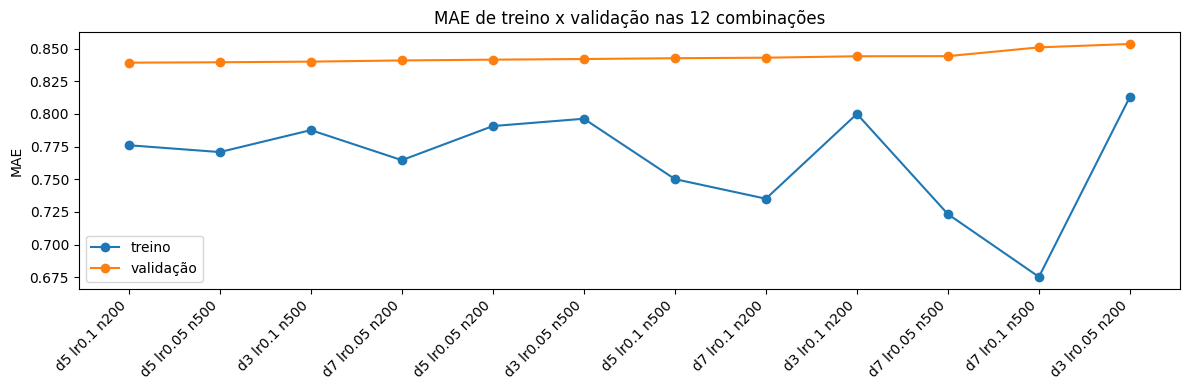

In [21]:
resultados = pd.DataFrame(busca.cv_results_)

tabela_combinacoes = pd.DataFrame({
    "max_depth": resultados["param_max_depth"],
    "learning_rate": resultados["param_learning_rate"],
    "n_estimators": resultados["param_n_estimators"],
    "MAE_treino": -resultados["mean_train_score"],      # volta para positivo
    "MAE_validacao": -resultados["mean_test_score"],
})
# quanto maior a diferença, maior o sinal de overfitting
tabela_combinacoes["diferenca"] = tabela_combinacoes["MAE_validacao"] - tabela_combinacoes["MAE_treino"]
tabela_combinacoes = tabela_combinacoes.sort_values("MAE_validacao").round(4).reset_index(drop=True)
display(tabela_combinacoes)

# gráfico treino x validação para cada combinação
rotulos = [f"d{r.max_depth} lr{r.learning_rate} n{r.n_estimators}" for r in tabela_combinacoes.itertuples()]
plt.figure(figsize=(12, 4))
plt.plot(rotulos, tabela_combinacoes["MAE_treino"], marker="o", label="treino")
plt.plot(rotulos, tabela_combinacoes["MAE_validacao"], marker="o", label="validação")
plt.xticks(rotation=45, ha="right")
plt.ylabel("MAE")
plt.title("MAE de treino x validação nas 12 combinações")
plt.legend()
plt.tight_layout()
plt.show()

## 15. Avaliação final: treino × teste

O `GridSearchCV` já retreina a melhor combinação com todo o período de treino.
Agora avaliamos esse modelo no **teste (2025–2026)**, que ele nunca viu.

Métricas:
- **MAE**: erro médio absoluto, em "sinistros" (ex.: 0,8 = erra em média 0,8 sinistro por zona/faixa);
- **RMSE**: parecido com o MAE, mas pune mais os erros grandes;
- **R²**: quanto da variação dos sinistros o modelo explica (1 = perfeito, 0 = igual a chutar a média).

,Treino,Teste,Baseline (teste)
MAE,0.817,0.805,0.822
RMSE,1.093,1.069,1.085
R²,0.330,0.273,0.252


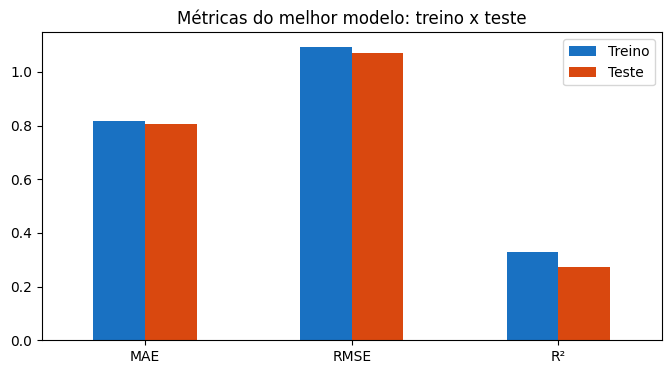

In [22]:
modelo = busca.best_estimator_

prev_treino = modelo.predict(X_treino)
prev_teste = modelo.predict(X_teste)

def metricas(real, previsto):
    return {
        "MAE": mean_absolute_error(real, previsto),
        "RMSE": np.sqrt(mean_squared_error(real, previsto)),
        "R²": r2_score(real, previsto),
    }

comparacao = pd.DataFrame({
    "Treino": metricas(y_treino, prev_treino),
    "Teste": metricas(y_teste, prev_teste),
    "Baseline (teste)": metricas(y_teste, baseline_teste),
}).round(3)
display(comparacao)

comparacao[["Treino", "Teste"]].plot(kind="bar", figsize=(8, 4), rot=0, color=["#1971c2", "#d9480f"])
plt.title("Métricas do melhor modelo: treino x teste")
plt.show()

### 15.1 Previsto × real no período de teste

Somamos as previsões de todas as zonas e faixas para cada dia e comparamos com o que realmente aconteceu.

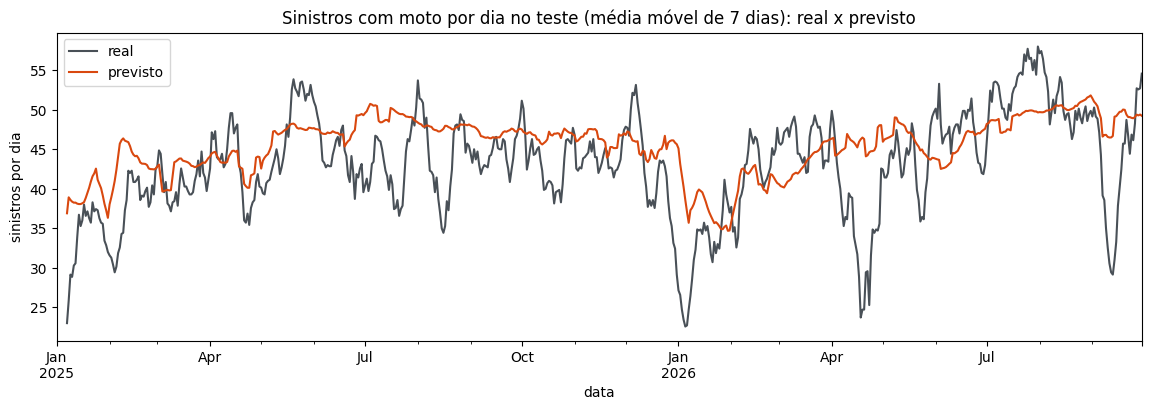

In [23]:
resultado_teste = treino_base[~eh_treino][["data", "zona", "faixa"]].copy()
resultado_teste["real"] = y_teste.values
resultado_teste["previsto"] = prev_teste

# total por dia; média móvel de 7 dias para suavizar o gráfico
por_dia = resultado_teste.groupby("data")[["real", "previsto"]].sum()
por_dia.rolling(7).mean().plot(figsize=(14, 4), color=["#495057", "#d9480f"])
plt.title("Sinistros com moto por dia no teste (média móvel de 7 dias): real x previsto")
plt.ylabel("sinistros por dia")
plt.show()

## 16. Quais variáveis mais pesam no risco?

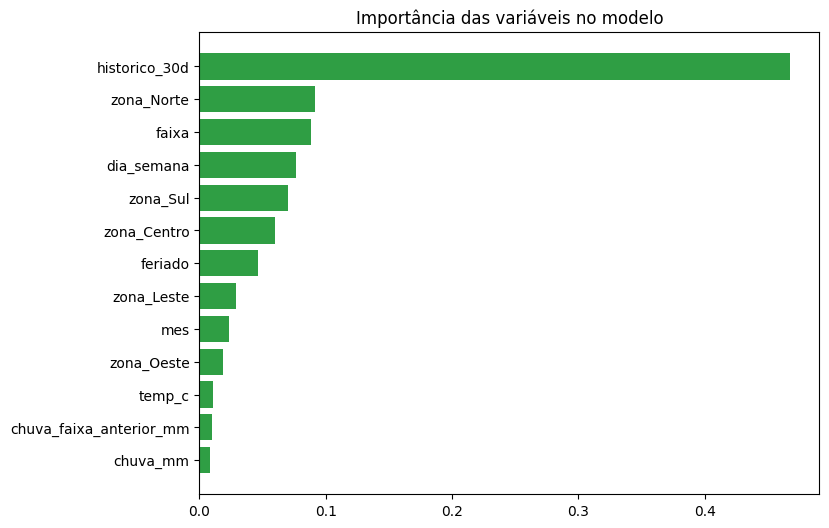

In [24]:
importancia = pd.Series(modelo.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8, 6))
plt.barh(importancia.index, importancia.values, color="#2f9e44")
plt.title("Importância das variáveis no modelo")
plt.show()

## 17. Transformando a previsão em nível de risco

O cidadão e os órgãos não precisam de "1,87 sinistros esperados", e sim de um **nível de risco**.
Definimos os cortes pelos quantis das previsões no treino:

| Nível | Faixa das previsões | Para o motociclista | Para os órgãos |
|---|---|---|---|
| 🟢 Baixo | 40% menores | condução normal | operação padrão |
| 🟡 Moderado | 40% a 70% | atenção redobrada | monitoramento |
| 🟠 Alto | 70% a 90% | reduzir velocidade, evitar corredor | reforçar patrulha na zona |
| 🔴 Crítico | 10% maiores | adiar a saída se possível | equipes de prontidão |

Para validar, verificamos no **teste** se os períodos classificados como mais arriscados realmente tiveram mais sinistros.

In [25]:
# pontos de corte: 40%, 70% e 90% das previsões de treino
cortes = np.quantile(prev_treino, [0.40, 0.70, 0.90])
niveis = ["Baixo", "Moderado", "Alto", "Crítico"]
print("Cortes (sinistros esperados):", cortes.round(2))

def nivel_de_risco(previsao):
    return pd.cut(previsao, bins=[-np.inf, *cortes, np.inf], labels=niveis)

resultado_teste["nivel"] = nivel_de_risco(prev_teste)

# no teste: a média REAL de sinistros deve crescer de Baixo -> Crítico
validacao_niveis = resultado_teste.groupby("nivel", observed=False).agg(
    periodos=("real", "size"),
    media_real=("real", "mean"),
    media_prevista=("previsto", "mean"),
).round(2)
display(validacao_niveis)

Cortes (sinistros esperados): [0.81 1.59 2.22]


,periodos,media_real,media_prevista
nivel,,,
Baixo,10333,0.43,0.45
Moderado,7817,1.12,1.17
Alto,5200,1.78,1.88
Crítico,2170,2.29,2.51


### 17.1 Simulando o RotaViva

A função abaixo é o "cérebro" da solução: recebe zona, data, faixa e chuva e devolve o nível de risco.
É essa lógica que a API e o app vão usar.

In [26]:
colunas_modelo = X.columns

def historico_recente(zona, faixa):
    # média da zona/faixa entre 60 e 31 dias antes do último dia da base
    serie = treino_base[(treino_base["zona"] == zona) & (treino_base["faixa"] == faixa)].sort_values("data")
    return serie["sinistros_moto"].iloc[-60:-30].mean()

def prever_risco(zona, data, faixa, chuva_mm=0.0, chuva_anterior_mm=0.0, temp_c=22.0, feriado=0):
    data = pd.Timestamp(data)
    linha = pd.DataFrame([{
        "faixa": faixa,
        "dia_semana": data.dayofweek,
        "mes": data.month,
        "feriado": feriado,
        "chuva_mm": chuva_mm,
        "chuva_faixa_anterior_mm": chuva_anterior_mm,
        "temp_c": temp_c,
        "historico_30d": historico_recente(zona, faixa),
        "zona_" + zona: 1,
    }]).reindex(columns=colunas_modelo, fill_value=0)   # demais zonas ficam 0
    previsao = modelo.predict(linha)[0]
    return round(float(previsao), 2), nivel_de_risco([previsao])[0]

# (zona, data, faixa, chuva na faixa, chuva na faixa anterior)
cenarios = [
    ("Sul",    "2026-11-20", 6, 0.0, 0.0),   # sexta, 18-21h, sem chuva
    ("Sul",    "2026-11-20", 2, 1.5, 0.0),   # sexta, 06-09h, chuva fraca
    ("Centro", "2026-11-22", 1, 0.0, 0.0),   # domingo, 03-06h
    ("Leste",  "2026-11-23", 6, 8.0, 3.0),   # segunda, 18-21h, chuva forte
]
for zona, data, faixa, chuva, chuva_ant in cenarios:
    prev, nivel = prever_risco(zona, data, faixa, chuva, chuva_ant)
    print(f"{zona:<7} {data}  faixa {faixa}  chuva {chuva:>4} mm  ->  "
          f"{prev:.2f} sinistros esperados  |  risco {nivel}")

Sul     2026-11-20  faixa 6  chuva  0.0 mm  ->  2.82 sinistros esperados  |  risco Crítico
Sul     2026-11-20  faixa 2  chuva  1.5 mm  ->  2.73 sinistros esperados  |  risco Crítico
Centro  2026-11-22  faixa 1  chuva  0.0 mm  ->  0.23 sinistros esperados  |  risco Baixo
Leste   2026-11-23  faixa 6  chuva  8.0 mm  ->  2.28 sinistros esperados  |  risco Crítico


## 18. Salvando o modelo

O modelo e os cortes dos níveis são salvos para serem usados pela API da CitizenTech (integração com as outras disciplinas).

In [27]:
import json

modelo.save_model("modelo_rotaviva.json")

with open("niveis_risco.json", "w", encoding="utf-8") as f:
    json.dump({"cortes": cortes.tolist(), "niveis": niveis, "colunas": list(colunas_modelo)},
              f, ensure_ascii=False, indent=2)

print("Modelo e cortes salvos.")

Modelo e cortes salvos.


## 19. Comparação entre os experimentos

| | Experimento 1 | Experimento 2 |
|---|---|---|
| Variáveis | calendário (com `ano`), chuva, temperatura, zona | calendário (sem `ano`), chuva, temperatura, zona + **`historico_30d`** |
| Melhor combinação | `max_depth=5`, `learning_rate=0.1`, `n_estimators=200` | ver seção 14 |

No experimento 1, o modelo empatou com o baseline e superestimou o período de teste em ~15%, porque não percebeu a queda de sinistros confirmados em 2025.
Os números do experimento 1 foram registrados abaixo, já que as saídas das células foram substituídas ao rodar o experimento 2.

In [28]:
# resultados registrados do experimento 1 (antes de adicionar historico_30d)
experimento_1 = {"MAE treino": 0.814, "MAE teste": 0.827, "RMSE teste": 1.082, "R² teste": 0.255}

experimento_2 = {
    "MAE treino": comparacao.loc["MAE", "Treino"],
    "MAE teste": comparacao.loc["MAE", "Teste"],
    "RMSE teste": comparacao.loc["RMSE", "Teste"],
    "R² teste": comparacao.loc["R²", "Teste"],
}

baseline = {
    "MAE treino": None,
    "MAE teste": comparacao.loc["MAE", "Baseline (teste)"],
    "RMSE teste": comparacao.loc["RMSE", "Baseline (teste)"],
    "R² teste": comparacao.loc["R²", "Baseline (teste)"],
}

pd.DataFrame({"Baseline": baseline, "Experimento 1": experimento_1, "Experimento 2": experimento_2}).round(3)

,Baseline,Experimento 1,Experimento 2
MAE treino,NaN,0.814,0.817
MAE teste,0.822,0.827,0.805
RMSE teste,1.085,1.082,1.069
R² teste,0.252,0.255,0.273
